In [1]:
from model.foveal_gat import FovealGAT, IOUFovealGAT
from gaze_datasets.reflacx import ReflacxGazePatchDataset
from feature_extraction.extractors import GazePatchFeatureExtractor
from node_encodings.sequence import GazeSinCosPosEncoding
from model.iou_xyt_gat_conv import CausalIOU_EuclideanTGATConv
from model.residual_sequential import MarkovResidualSequential
import model.readout as readouts
import only_gaze_confs as conf
import torch
from torch import nn
from torch.nn import functional as F
from torch_geometric.nn.norm import GraphNorm
from random import randint

/store/alutfi/py_venvs/gat2/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


choosing least busy GPU...
running on cuda:0


In [2]:
gaze_dataset_pth = conf.reflacx_gaze_dataset_pth
desired_label = 'Atelectasis'

In [3]:
ds = ReflacxGazePatchDataset(gaze_dataset_pth, desired_label, target_fixation_keys=('t', 'x', 'y', 'top_left', 'bottom_right'))

feat_ext = GazePatchFeatureExtractor(conf.fe_tail_feat_ext,
                                     conf.fe_state_dict_pth,
                                     conf.fe_channels,
                                     conf.fe_act,
                                     conf.fe_norm,
                                     conf.fe_bias,
                                     conf.fe_w_init_f,
                                     conf.device)

max_len = conf.reflacx_max_len
seq_encoding_featcount = conf.seq_encoding_feat_count
seq_encoding = GazeSinCosPosEncoding(max_len, seq_encoding_featcount)

In [57]:
fixations, gaze_ps, label = ds[randint(0, len(ds) - 1)]
fixations = fixations.to(conf.device)
gaze_ps = gaze_ps.unsqueeze(1).to(conf.device)
label = label.to(conf.device)
fixations.shape, gaze_ps.shape, label

(torch.Size([56, 7, 1, 1]),
 torch.Size([56, 1, 31, 31]),
 tensor(1., device='cuda:0'))

In [5]:
feats = feat_ext(gaze_ps.to(conf.device))
seqs = seq_encoding(fixations.shape[0], adjust_dim=True).to(conf.device)

feats.shape, seqs.shape

(torch.Size([99, 128, 1, 1]), torch.Size([99, 16, 1, 1]))

In [7]:
sd = torch.load('/store/alutfi/dev/models/iou/xytreflacx_1_ang_res_256_Atelectasis_BCEWithLogitsLoss_AdamW/20261005_0553/session_0/best_xytreflacx_1_ang_res_256_Atelectasis_BCEWithLogitsLoss_AdamW.pt')


In [9]:
from model.iou_xyt_gat_conv import IOU_XYTGATConv
from model.gat_conv import CausalGATConv
from model.readout import CausalReadout
from model.tools import adjust_args_to_len
from model.xyt_gat_conv import CausalXYTGATConv, CausalEuclideanTGATConv, CausalSummaryXYTGATConv, CausalEuclideanSummaryTGATConv
from model.iou_xyt_gat_conv import CausalIOU_XYTGATConv, CausalIOU_EuclideanTGATConv, CausalSummaryIOU_XYTGATConv, CausalEuclideanSummaryIOU_TGATConv
from model.residual_sequential import MarkovResidualSequential
from gaze_datasets.dataset_tools import all_pairs, get_xyt_pair_matrices, get_euclidean_encodings, get_bbox_iou_encodings
from model.tools import init_weights

In [10]:
class VIZ_CausalIOU_XYTGATConv(IOU_XYTGATConv):
    def __init__(self,
                 in_channels,
                 out_channels,
                 att_heads,
                 xy_heads_ratio=0.2,
                 t_heads_ratio=0.1,
                 iou_heads_ratio=0.2,
                 act_att=F.leaky_relu,
                 act_gat=F.elu,
                 norm=GraphNorm,
                 dropout=0.1,
                 bias=True,
                 w_init_f=lambda w: nn.init.xavier_uniform_(w),
                 device='cpu'):
        super().__init__(in_channels,
                         out_channels,
                         att_heads,
                         xy_heads_ratio,
                         t_heads_ratio,
                         iou_heads_ratio,
                         act_att,
                         act_gat,
                         norm,
                         dropout,
                         bias,
                         w_init_f,
                         device)
    """A GATConv layer for a causal graph,
    where each node sees only itself and their predecessors
    """
    def forward(self, x):
        nodes, splits, xy_mats, t_mats, iou_mats = x
        # normalize graph
        batch_idx = torch.cat([torch.ones(s, dtype=torch.int) * i
                               for i, s in enumerate(splits)]).to(self.device)
        nodes = torch.transpose(nodes, 1, 0)
        nodes = self.dropout(self.norm(nodes, batch_idx.to(torch.long)))
        nodes = torch.transpose(nodes, 1, 0)
        
        # generate adjacency matrix for whole batch
        subnodes = torch.split(nodes, splits, dim=1)
        adjs = [IOU_XYTGATConv.adj_mat(ns) for ns in subnodes]

        # generate raw semantic scores
        sem_raw_scores = [self.act_att(self.att_scores(adj)) for adj in adjs]
        
        # generate raw XY scores
        xy_raw_scores = [self.act_att(self.xy_scores(xy_mat)) for xy_mat in xy_mats]

        # generate raw T scores
        t_raw_scores = [self.act_att(self.t_scores(t_mat)) for t_mat in t_mats]

        # generate raw IOU scores
        iou_raw_scores = [self.act_att(self.iou_scores(iou_mat)) for iou_mat in iou_mats]
        
                
        
        rawscores = [torch.cat((sem, xy, t, iou), dim=0)
                     for sem, xy, t, iou in zip(sem_raw_scores,
                                           xy_raw_scores,
                                           t_raw_scores,
                                           iou_raw_scores)]        

        # set upper triangle to zero, so a node doesn't see future nodes
        adj_mask = [torch.tril(torch.ones(rs.shape,
                                dtype=torch.bool,
                                device=self.device))
                    for rs in rawscores]
        masked_scores = [torch.where(am,
                                     rs,
                                     torch.tensor(float('-inf'),
                                     device=self.device))
                         for am, rs in zip(adj_mask, rawscores)]

        # generate final att weights
        att_ws = [F.softmax(ms, dim=-1) for ms in masked_scores]

        # pass messages and generate output nodes
        gatconv = [torch.matmul(sn, s) for sn, s in zip(subnodes, att_ws)]
        gatconv = torch.cat(gatconv, -1)
        gatconv = gatconv.reshape((gatconv.shape[0] * gatconv.shape[1], gatconv.shape[2]))
        return self.act_gat(self.node_update(gatconv)), masked_scores


class VIZ_CausalIOU_EuclideanTGATConv(VIZ_CausalIOU_XYTGATConv):
    """A GATConv layer for a causal graph,
        where each node sees only itself and their predecessors
    """
    def __init__(self,
                 in_channels,
                 out_channels,
                 att_heads,
                 xy_heads_ratio=0.2,
                 t_heads_ratio=0.1,
                 iou_heads_ratio=0.2,
                 act_att=F.leaky_relu,
                 act_gat=F.elu,
                 norm=GraphNorm,
                 dropout=0.1,
                 bias=True,
                 w_init_f=lambda w: nn.init.xavier_uniform_(w),
                 device='cpu'):
        super().__init__(in_channels,
                         out_channels,
                         att_heads,
                         xy_heads_ratio,
                         t_heads_ratio,
                         iou_heads_ratio,
                         act_att,
                         act_gat,
                         norm,
                         dropout,
                         bias,
                         w_init_f,
                         device)

        xy_heads = self.xy_scores.out_channels
        self.xy_scores = nn.Conv2d(7,# x1, y1, x2, y2, deltax, deltay, euc_dist
                                   xy_heads,
                                   1,
                                   device=device,
                                   bias=bias)

In [11]:
class VIZ_MarkovResidualSequential(nn.Sequential):
    """Extension of nn.Sequential class to allow keeping residual tensors"""
    def __init__(self, output_levels, residual_levels, gat_conv, *args):
        """param:levels is an list of indices of layers which outputs are to be kept
        """
        super(VIZ_MarkovResidualSequential, self).__init__(*args)
        self.output_lvls = output_levels
        self.residual_lvls = residual_levels
        self.gat_conv = gat_conv
                

    def add_conv(self,
                 name,
                 in_channels,
                 **kwargs):
        self.add_module(name,
                        self.gat_conv(in_channels,
                                      **kwargs))


    def forward(self, x):
        first_nodes, splits, *args = x
        nodes = first_nodes

        result = []
        scores = []
        for i, module in enumerate(self):
            residual = nodes
            nodes, att_ws = module((nodes, splits, *args))
            if i > 0 and self.residual_lvls[i]:
                nodes = nodes + residual
            if i in self.output_lvls:
                result.append(nodes)
                scores.append(att_ws)
        return result, scores

In [12]:
from model.grapher import GazeGrapher

In [13]:
class VIZ_IOU_EuclideanTGazeGrapher(GazeGrapher):
    gat_convs = [CausalIOU_EuclideanTGATConv.__name__,
                 CausalEuclideanSummaryIOU_TGATConv.__name__]
    def __init__(self,
                 gat_conv=CausalIOU_EuclideanTGATConv,
                 residual_sequential=MarkovResidualSequential,
                 layers=8,
                 output_gat_levels=None,
                 residual_gat_levels=None,
                 att_heads=8,
                 gat_conv_args={'channels': 256,
                                'xy_heads_ratio': 0.2,
                                't_heads_ratio': 0.1,
                                'iou_heads_ratio': 0.2,
                                'act_att': F.leaky_relu,
                                'act_gat': F.elu,
                                'norm': GraphNorm,
                                'dropout': 0.1,
                                'bias': True,
                                'w_init_f': lambda w: nn.init.xavier_uniform_(w)},
                 device='cpu'):
        super().__init__(gat_conv,
                         residual_sequential,
                         layers,
                         output_gat_levels,
                         residual_gat_levels,
                         att_heads,
                         gat_conv_args,
                         device)

    def forward(self, x):
        nodes, splits, fixations, bboxes = x
        xy_mats, t_mats = get_xyt_pair_matrices(fixations, splits)
        xy_mats = [get_euclidean_encodings(xym) for xym in xy_mats]
        iou_mats = get_bbox_iou_encodings(bboxes, splits)
        graphs, scores = self.gats((nodes, splits, xy_mats, t_mats, iou_mats))
        return graphs, scores

In [14]:
class VIZ_FovealGAT(nn.Module):
    def __init__(self,
                 feat_extractor,
                 encoder,
                 gat_conv=CausalGATConv,
                 residual_sequential=MarkovResidualSequential,
                 gat_layers=8,
                 output_gat_levels=None,
                 residual_gat_levels=None,
                 gat_att_heads=8,
                 gat_conv_args={'channels': 256,
                                'act_att': F.leaky_relu,
                                'act_gat': F.elu,
                                'norm': GraphNorm,
                                'dropout': 0.1,
                                'bias': True,
                                'w_init_f': lambda w: nn.init.xavier_uniform_(w)},
                 readout=CausalReadout,
                 ro_hidden_features=[1024, 1024, 1024],
                 out_channels = 1,
                 ro_act=nn.GELU,
                 ro_pred_act=nn.Identity,
                 ro_dropout=0.0,
                 ro_norm=nn.GroupNorm,
                 ro_bias=True,
                 ro_w_init_f=lambda w: nn.init.kaiming_uniform_(w, nonlinearity='relu'),
                 device='cpu'):
        super(VIZ_FovealGAT, self).__init__()
        self.device=device
        self.gat_conv = gat_conv

        if feat_extractor is None:
            feat_extractor = GazePatchFeatureExtractor(state_dict_pth='../pretrained/pvig_ti_224_gelu.pt',
                                                       w_init_f=lambda w: nn.init.kaiming_uniform_(w, nonlinearity='relu'),
                                                       device=device)
        self.feat_ext = feat_extractor
        self.encoder = encoder

        node_dims = self.feat_ext.head[-3].in_channels + self.encoder.feature_count + 3 #x, y, t
        self.expand_dims = nn.Conv1d(node_dims, gat_conv_args['channels'], 1).to(self.device)
        init_weights(self.expand_dims, nn.init.xavier_uniform_)

        self.grapher = VIZ_IOU_EuclideanTGazeGrapher(gat_conv,
                                                             residual_sequential,
                                                             gat_layers,
                                                             output_gat_levels,
                                                             residual_gat_levels,
                                                             gat_att_heads,
                                                             gat_conv_args,
                                                             device=device)

        ro_in_channels = sum([c.node_update.out_channels
                              for i, c in enumerate(self.grapher.gats)
                              if i in self.grapher.gats.output_lvls])
        ro_channels = [ro_in_channels] + ro_hidden_features
        self.readout = readout(ro_channels,
                               out_channels,
                               ro_act,
                               ro_pred_act,
                               ro_dropout,
                               ro_norm,
                               ro_bias,
                               w_init_f=ro_w_init_f,
                               device=device)

    def forward(self, x):
        pass

In [52]:
class VIZ_IOUFovealGAT(VIZ_FovealGAT):
    def __init__(self,
                 feat_extractor,
                 encoder,
                 gat_conv=CausalGATConv,
                 residual_sequential=MarkovResidualSequential,
                 gat_layers=8,
                 output_gat_levels=None,
                 residual_gat_levels=None,
                 gat_att_heads=8,
                 gat_conv_args={'channels': 256,
                                'act_att': F.leaky_relu,
                                'act_gat': F.elu,
                                'norm': GraphNorm,
                                'dropout': 0.1,
                                'bias': True,
                                'w_init_f': lambda w: nn.init.xavier_uniform_(w)},
                 readout=CausalReadout,
                 ro_hidden_features=[1024, 1024, 1024],
                 out_channels = 1,
                 ro_act=nn.GELU,
                 ro_pred_act=nn.Identity,
                 ro_dropout=0.0,
                 ro_norm=nn.GroupNorm,
                 ro_bias=True,
                 ro_w_init_f=lambda w: nn.init.kaiming_uniform_(w, nonlinearity='relu'),
                 device='cpu'):
        super().__init__(feat_extractor,
                         encoder,
                         gat_conv,
                         residual_sequential,
                         gat_layers,
                         output_gat_levels,
                         residual_gat_levels,
                         gat_att_heads,
                         gat_conv_args,
                         readout,
                         ro_hidden_features,
                         out_channels,
                         ro_act,
                         ro_pred_act,
                         ro_dropout,
                         ro_norm,
                         ro_bias,
                         ro_w_init_f,
                         device)
    
    def forward(self, x):
        splits, fixations, patches, labels = x
        fixations = fixations.to(self.device)
        patches = patches.to(self.device)
        labels = labels.to(self.device)

        fixations, bboxes = torch.split(fixations, (3, 4), dim=1)
        bboxes = bboxes.squeeze(-1).squeeze(-1).transpose(1, 0)
                
        feats = self.feat_ext(patches)
        encodings = self.encoder(splits, adjust_dim=True).to(self.device)

        nodes = torch.cat([fixations, encodings, feats], 1).float()
        nodes = nodes.squeeze(-1).squeeze(-1).permute((1, 0))
        nodes = self.expand_dims(nodes)
        
        graphs, scores = self.grapher((nodes, splits, fixations, bboxes))
        predictions = self.readout((graphs, splits))
        return predictions, scores, graphs

In [53]:
grph_gat_conv = VIZ_CausalIOU_EuclideanTGATConv
grph_res_seq = VIZ_MarkovResidualSequential
grph_layers = 8
grph_channels = 384
grph_residual_gat_levels = [False, True, True, True, True, True, True, True]
grph_output_gat_levels = None
grph_att_heads = [16, 8, 8, 8, 8, 8, 8, 8]
grph_xy_heads_ratio=0.2
grph_t_heads_ratio=0.1
grph_iou_heads_ratio=0.2
grph_act_att = F.leaky_relu
grph_act_gat = F.elu
grph_norm = GraphNorm
grph_dropout = 0.3
grph_bias = True
grph_w_init_f = lambda w: nn.init.xavier_uniform_(w)

gat_conv_args={'channels': grph_channels,
               'xy_heads_ratio': grph_xy_heads_ratio,
               't_heads_ratio': grph_t_heads_ratio,
               'iou_heads_ratio': grph_iou_heads_ratio,
               'act_att': grph_act_att,
               'act_gat': grph_act_gat,
               'norm': grph_norm,
               'dropout': grph_dropout,
               'bias': grph_bias,
               'w_init_f': grph_w_init_f}


readout = readouts.CausalReadout
ro_channels = [-1, 512, 256, 128, 64]
ro_hidden_features = ro_channels[1:]
ro_out_channels = 1
ro_hidden_act = nn.GELU
ro_pred_act = nn.Identity
ro_dropout = 0.3
ro_norm = nn.GroupNorm
ro_bias = True
ro_w_init_f = lambda w: nn.init.kaiming_uniform_(w, nonlinearity='relu')

In [17]:
grph_att_heads

[16, 8, 8, 8, 8, 8, 8, 8]

In [54]:
model = VIZ_IOUFovealGAT(feat_ext,
                     seq_encoding,
                     VIZ_CausalIOU_EuclideanTGATConv,
                     VIZ_MarkovResidualSequential,
                     grph_layers,
                     grph_output_gat_levels,
                     grph_residual_gat_levels,
                     grph_att_heads,
                     gat_conv_args,
                     readout,
                     ro_hidden_features,
                     ro_out_channels,
                     ro_hidden_act,
                     ro_pred_act,
                     ro_dropout,
                     ro_norm,
                     ro_bias,
                     ro_w_init_f,
                     conf.device)

In [55]:
model.load_state_dict(sd['model'])

<All keys matched successfully>

In [71]:
p, scores, graphs = model(([fixations.shape[0]], fixations, gaze_ps, label))
p.shape, [[s.shape for s in ss] for ss in scores], [g.shape for g in graphs]

(torch.Size([1]),
 [[torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])],
  [torch.Size([24, 56, 56])]],
 [torch.Size([384, 56]),
  torch.Size([384, 56]),
  torch.Size([384, 56]),
  torch.Size([384, 56]),
  torch.Size([384, 56]),
  torch.Size([384, 56]),
  torch.Size([384, 56]),
  torch.Size([384, 56])])

In [72]:
scores = [s[0] for s in scores]

In [73]:
scores = [s.split((16, 3, 2, 3), dim=0) for s in scores]
[[x.shape for x in s] for s in scores]

[[torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])],
 [torch.Size([16, 56, 56]),
  torch.Size([3, 56, 56]),
  torch.Size([2, 56, 56]),
  torch.Size([3, 56, 56])]]

In [24]:
from matplotlib import pyplot as plt

In [25]:
torch.mean(scores[0][0], dim=0).shape

torch.Size([99, 99])

In [108]:
scores = [[torch.mean(x, dim=0).detach().to('cpu') for x in s] for s in scores]
[[x.shape for x in s] for s in scores]

[[torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])],
 [torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56]),
  torch.Size([56, 56])]]

In [35]:
x = torch.cat([scores[0][0].unsqueeze(0), scores[1][0].unsqueeze(0)], dim=0)
x.shape

torch.Size([2, 99, 99])

In [43]:
x = scores[0][3]
x.shape

torch.Size([99, 99])

In [46]:
torch.min(x)

tensor(-inf)

In [47]:
xmax = torch.max(x)
xmin = torch.min(x[x != torch.tensor(float('-inf'))])
xmax, xmin

(tensor(0.1874), tensor(0.0012))

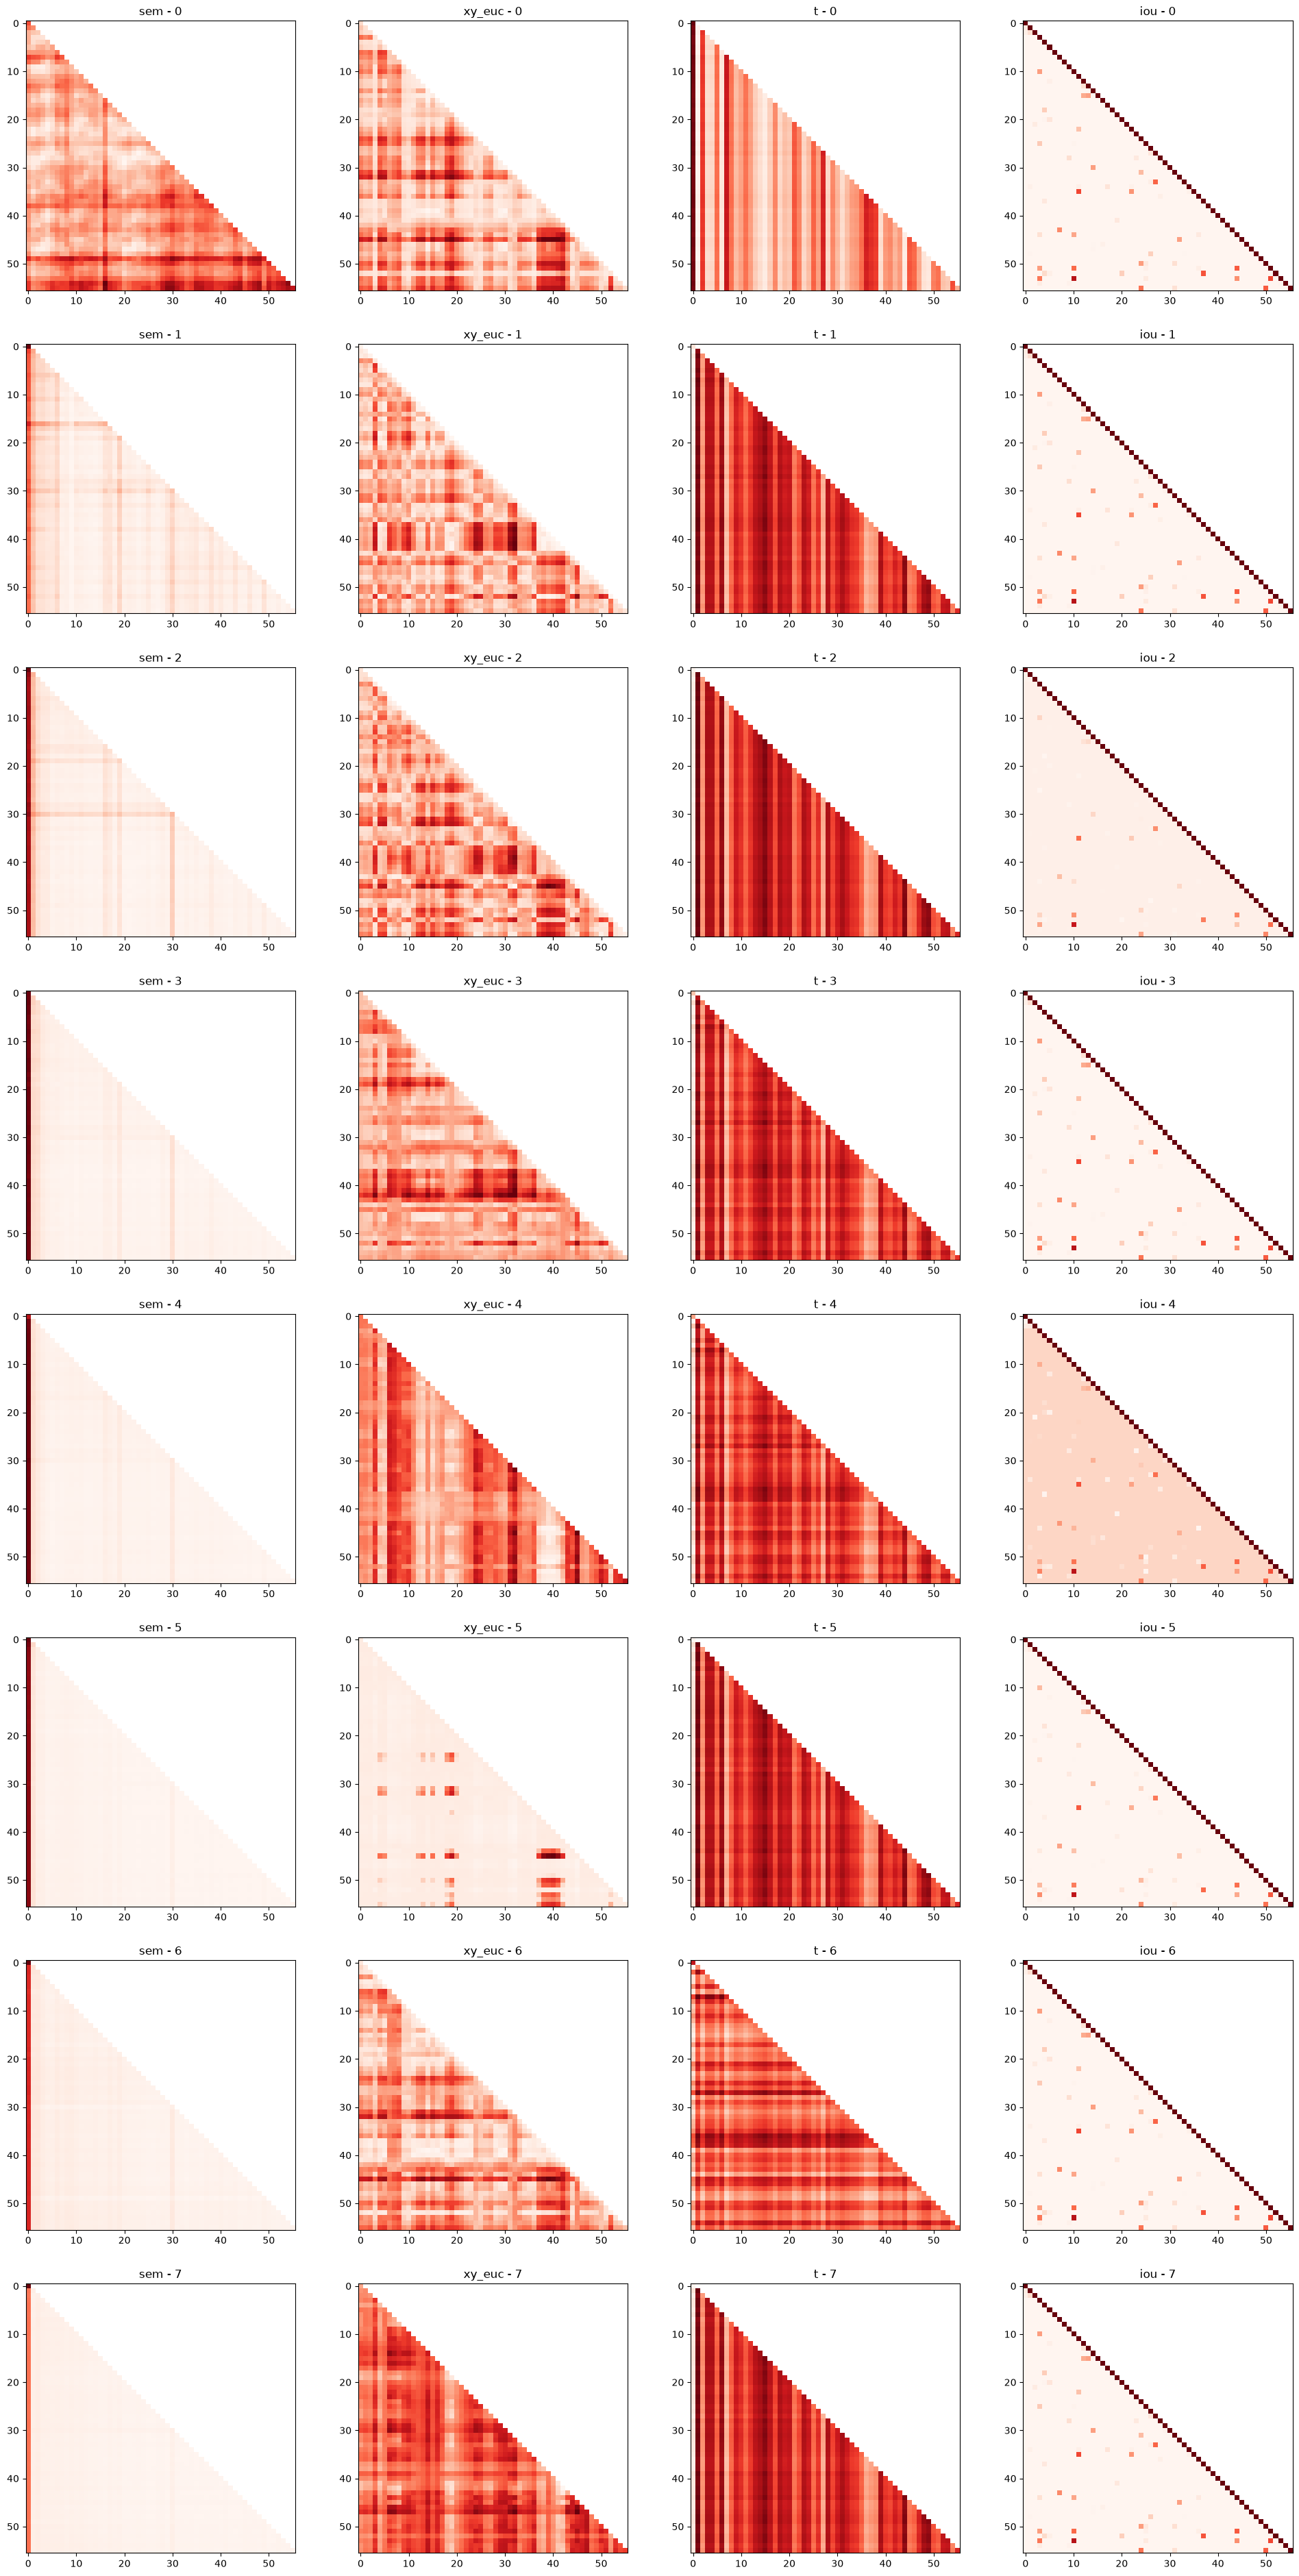

In [109]:
import numpy
_, plots = plt.subplots(8, 4, figsize=(24, 48))
if plots.__class__ != numpy.ndarray:
    plots = numpy.expand_dims(numpy.array(plots), 0)
for i in range(8):
    for j in range(4):
        s = scores[i][j]

        smax = torch.max(s)
        smin = torch.min(s[s != torch.tensor(float('-inf'))])

        s = (s - smin) / (smax - smin)
        
        plots[i][j].set_title('{} - {}'.format(['sem', 'xy_euc', 't', 'iou'][j], i))
        plots[i][j].imshow(s, cmap='Reds')
    

plt.show()

In [ ]:
graphs

[torch.Size([8, 99, 99]),
 torch.Size([8, 99, 99]),
 torch.Size([8, 99, 99]),
 torch.Size([8, 99, 99])]

In [87]:
s = scores[0][0].detach().to('cpu')
s = torch.softmax(s, dim=-1)
s.shape

torch.Size([16, 56, 56])

In [121]:
s

tensor([[1.0000,   -inf,   -inf,  ...,   -inf,   -inf,   -inf],
        [0.0540, 1.0000,   -inf,  ...,   -inf,   -inf,   -inf],
        [0.0381, 0.1279, 1.0000,  ...,   -inf,   -inf,   -inf],
        ...,
        [0.0000, 0.0000, 0.0000,  ..., 1.0000,   -inf,   -inf],
        [0.0000, 0.0000, 0.0000,  ..., 0.0147, 1.0000,   -inf],
        [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 1.0000]])

In [97]:
ns = torch.matmul(s, graphs[0].detach().to('cpu').transpose(1, 0))
ns.shape

torch.Size([3, 56, 384])

In [120]:
torch.min(graphs[0]), torch.min(ns)

(tensor(-1., device='cuda:0', grad_fn=<MinBackward1>), tensor(-1.))

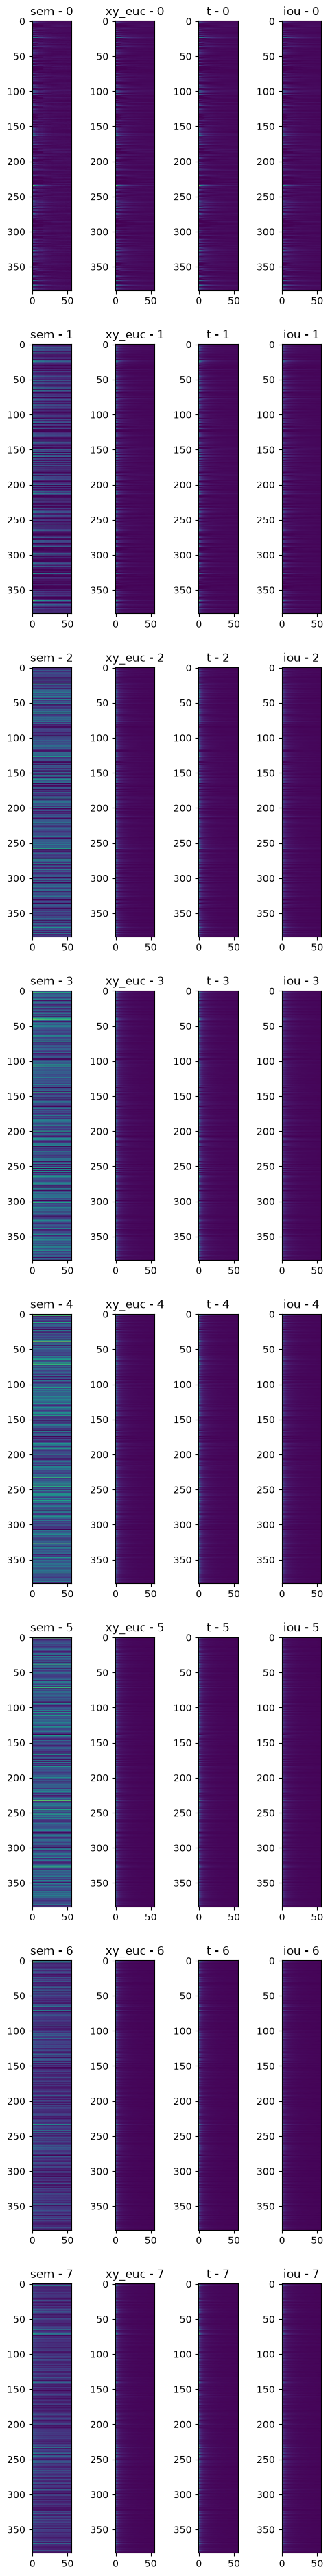

In [93]:
import numpy
_, plots = plt.subplots(8, 4, figsize=(6, 48))
if plots.__class__ != numpy.ndarray:
    plots = numpy.expand_dims(numpy.array(plots), 0)
for i in range(8):
    for j in range(4):
        s = scores[i][j].detach().to('cpu')

        s = torch.softmax(s, dim=-1)

        ns = torch.matmul(s, graphs[i].detach().to('cpu').transpose(1, 0))
        ns = torch.mean(ns, dim=0).transpose(1,0)
        
        plots[i][j].set_title('{} - {}'.format(['sem', 'xy_euc', 't', 'iou'][j], i))
        plots[i][j].imshow(ns)
    

plt.show()

In [29]:
fixations = fixations.squeeze(-1).squeeze(-1)
xy, tbbs = fixations.split((2, 5), dim=1)
t, bbs = tbbs.split((1, 4), dim=1)
l, t, r, b = bbs.split(1, dim=1)
xy.shape, t.shape, l.shape, t.shape, r.shape, b.shape

(torch.Size([99, 2]),
 torch.Size([99, 1]),
 torch.Size([99, 1]),
 torch.Size([99, 1]),
 torch.Size([99, 1]),
 torch.Size([99, 1]))

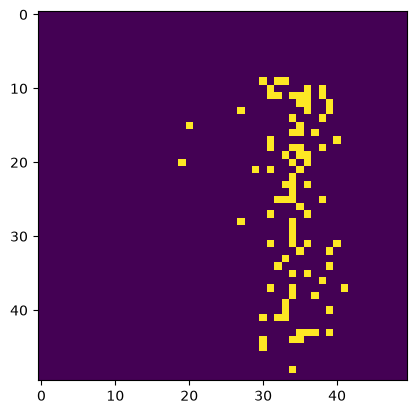

In [30]:
canvas = torch.zeros((50, 50))
normxy = torch.floor(xy * 50).to(torch.uint8).to('cpu')
normxy = [(int(y), int(x)) for x, y in normxy[:]]
normxy
for xy in normxy:
    canvas[xy] = 1.0
plt.imshow(canvas)
